# Day 75: Phase 4 Buffer — Drill Your Weak Spots

## Plan for today
1. **Weak spot A:** precision vs recall (and ROC vs PR), redone on a **new dataset**
2. **Weak spot B:** bias-variance tradeoff, redone on a **new dataset**
3. **Interview prep:** explain both out loud (scripts below)
4. **Kaggle-style baseline:** a Random Forest pipeline that writes a `submission.csv`
5. **GitHub:** organize Phase 4 into one clean repo with a README

> **Data note (all in `data/`):**
> - `breast_cancer_imbalanced.csv`: real breast cancer data from scikit-learn, with malignant cases **downsampled to 30 of 387 rows (7.8%)** on purpose, to make them rare
> - `diabetes.csv`: real diabetes data from scikit-learn (442 patients, target = disease progression)
> - `titanic.csv`: the real Titanic training data

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (StratifiedKFold, KFold, cross_val_predict,
                                     cross_validate, cross_val_score, train_test_split)
from sklearn.metrics import (accuracy_score, roc_auc_score, average_precision_score,
                             precision_score, recall_score, precision_recall_curve)

# Part A: Precision vs Recall (new dataset: breast cancer)

**Theory**
- **Precision:** of the cases I flagged, how many were truly positive
- **Recall:** of the truly positive cases, how many I caught
- Lowering the decision threshold raises recall and usually lowers precision
- When positives are rare, **accuracy can look great while the model misses most positives**

In [2]:
bc = pd.read_csv("data/breast_cancer_imbalanced.csv")
X = bc.drop(columns="malignant")
y = bc["malignant"]
print(X.shape, "| malignant:", int(y.sum()), "(" + str(round(y.mean() * 100, 1)) + "%)")

(387, 30) | malignant: 30 (7.8%)


### A1: The accuracy trap

In [3]:
# Out-of-fold probabilities for every row (each row is predicted by a model that never saw it)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv = StratifiedKFold(5, shuffle=True, random_state=42)
p = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]

print("Always say benign:", round(1 - y.mean(), 3))
print("Model accuracy:   ", round(accuracy_score(y, p >= 0.5), 3))
print("Cancers caught:", int(((p >= 0.5) & (y == 1)).sum()), "of", int(y.sum()))

Always say benign: 0.922
Model accuracy:    0.979
Cancers caught: 23 of 30


### A2: ROC AUC vs Average Precision

In [4]:
print("ROC AUC:", round(roc_auc_score(y, p), 3))
print("Average Precision:", round(average_precision_score(y, p), 3))
print("Random-guess AP:", round(y.mean(), 3))

ROC AUC: 0.956
Average Precision: 0.913
Random-guess AP: 0.078


### A3: The threshold tradeoff

In [5]:
for t in [0.5, 0.3, 0.1]:
    f = p >= t
    pr, rc = precision_score(y, f), recall_score(y, f)
    print(f"t={t}: precision {pr:.3f} | recall {rc:.3f} | flagged {f.sum()}")

t=0.5: precision 0.958 | recall 0.767 | flagged 24
t=0.3: precision 0.962 | recall 0.833 | flagged 26
t=0.1: precision 0.718 | recall 0.933 | flagged 39


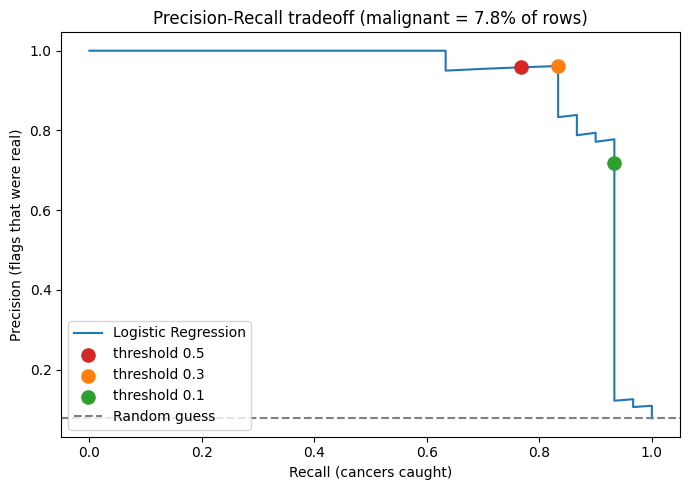

In [6]:
precision, recall, thresholds = precision_recall_curve(y, p)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, color="#1f77b4", label="Logistic Regression")
for t, color in [(0.5, "#d62728"), (0.3, "#ff7f0e"), (0.1, "#2ca02c")]:
    f = p >= t
    plt.scatter(recall_score(y, f), precision_score(y, f), s=90, color=color, zorder=3, label="threshold " + str(t))
plt.axhline(y.mean(), color="gray", linestyle="--", label="Random guess")
plt.xlabel("Recall (cancers caught)")
plt.ylabel("Precision (flags that were real)")
plt.title("Precision-Recall tradeoff (malignant = 7.8% of rows)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig("images/precision_recall_tradeoff.png", dpi=150)
plt.show()

# Part B: Bias-Variance Tradeoff (new dataset: diabetes)

**Theory**
- **Bias:** error from a model that is too simple (it misses the pattern), this is **underfitting**
- **Variance:** error from a model that is too sensitive to the training data, this is **overfitting**
- Simple model: high bias, low variance. Complex model: low bias, high variance
- Quick check: compare **train score** and **cross-validation score**
  - both low = bias problem
  - train high, CV low = variance problem

In [7]:
dia = pd.read_csv("data/diabetes.csv")
Xd = dia.drop(columns="progression")
yd = dia["progression"]
kf = KFold(5, shuffle=True, random_state=42)
print(Xd.shape)

(442, 10)


### B1: Does more complexity help?

In [8]:
# Polynomial degree 1 = straight line, 2 and 3 = more flexible curves
rows = []
for deg in [1, 2, 3]:
    poly = PolynomialFeatures(deg, include_bias=False)
    m = make_pipeline(StandardScaler(), poly, LinearRegression())
    out = cross_validate(m, Xd, yd, cv=kf, scoring="r2", return_train_score=True)
    tr, te = out["train_score"].mean(), out["test_score"].mean()
    rows.append((deg, tr, te))
    print(f"degree {deg}: train R2 {tr:.3f} | CV R2 {te:.3f}")

degree 1: train R2 0.520 | CV R2 0.478
degree 2: train R2 0.609 | CV R2 0.366
degree 3: train R2 0.880 | CV R2 -42.933


### B2: Regularization lowers the variance

In [9]:
ridge_rows = []
for a in [1, 10, 100, 1000]:
    poly = PolynomialFeatures(3, include_bias=False)
    m = make_pipeline(StandardScaler(), poly, Ridge(alpha=a))
    out = cross_validate(m, Xd, yd, cv=kf, scoring="r2", return_train_score=True)
    tr, te = out["train_score"].mean(), out["test_score"].mean()
    ridge_rows.append((a, tr, te))
    print(f"alpha {a}: train R2 {tr:.3f} | CV R2 {te:.3f}")

alpha 1: train R2 0.791 | CV R2 -0.828


alpha 10: train R2 0.741 | CV R2 -0.025


alpha 100: train R2 0.667 | CV R2 0.327
alpha 1000: train R2 0.547 | CV R2 0.383


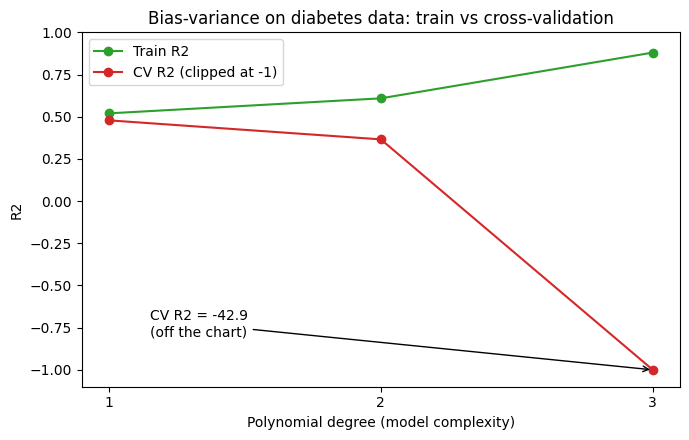

In [10]:
# Chart (the degree-3 CV score is far below the axis, so it is shown as a label)
degs = [r[0] for r in rows]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(degs, [r[1] for r in rows], marker="o", color="#2ca02c", label="Train R2")
ax.plot(degs, [max(r[2], -1) for r in rows], marker="o", color="#d62728", label="CV R2 (clipped at -1)")
ax.annotate("CV R2 = " + str(round(rows[2][2], 1)) + "\n(off the chart)", (3, -1), xytext=(1.15, -0.8),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xticks(degs)
ax.set_xlabel("Polynomial degree (model complexity)")
ax.set_ylabel("R2")
ax.set_ylim(-1.1, 1.0)
ax.set_title("Bias-variance on diabetes data: train vs cross-validation")
ax.legend()
plt.tight_layout()
plt.savefig("images/bias_variance_degree_sweep.png", dpi=150)
plt.show()

# Interview prep: say it out loud
> Practice each one out loud, with a timer. If you stumble, write down where, then try again.

### Bias vs variance (about 40 seconds)
"Bias is error from a model that is too simple. It misses the real pattern, like drawing a straight line through a curve. Variance is error from a model that is too sensitive to its training data, like a student who memorizes the answers instead of learning the idea. Simple models have high bias and low variance. Complex models have low bias and high variance. I want the middle. To check, I compare the training score with the cross-validation score. If both are low, it is a bias problem. If training is high and cross-validation is low, it is a variance problem. On the diabetes data, a straight line scored R-squared 0.478 in cross-validation. A degree-3 curve scored 0.88 on training but negative 42.9 in cross-validation."

### Precision vs recall (about 40 seconds)
"Precision asks: of everything I flagged, how much was really positive? Recall asks: of everything that was really positive, how much did I catch? Think of a smoke alarm. High recall means it rarely misses a fire. High precision means it rarely rings for nothing. Lowering the threshold raises recall but lowers precision. Which one matters more depends on the cost of a mistake. For cancer screening, I care most about recall. For a spam filter, I care most about precision. On my test, at threshold 0.5 the precision was 0.958 and recall 0.767. At threshold 0.1, recall rose to 0.933 and precision fell to 0.718."

### Self-test (answer without looking)
- Why can 98% accuracy be a bad result?
- What does a train score of 0.88 and a CV score of -42.9 tell you?
- Which do you lower, the threshold or the model complexity, to catch more positives?
- What is the AP of a random guess on this data, and why?

# Kaggle-style baseline: Random Forest in a pipeline

> **Honest note:** I cannot download the competition's `test.csv` or submit to Kaggle from here.
> So the baseline below is trained on `titanic.csv`, and the submission file is written for a **held-out 20% of those rows** as a stand-in.
> To make a real entry: download `train.csv` and `test.csv` from the Kaggle "Titanic: Machine Learning from Disaster" competition,
> run `make_submission` on the real `test.csv`, and upload the file.

In [11]:
titanic = pd.read_csv("data/titanic.csv")
numeric_cols = ["Age", "SibSp", "Parch", "Fare"]
categorical_cols = ["Pclass", "Sex", "Embarked"]
features = numeric_cols + categorical_cols

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols),
])

Xt = titanic[features]
yt = titanic["Survived"]
ids = titanic["PassengerId"]
Xt_train, Xt_test, yt_train, yt_test, ids_train, ids_test = train_test_split(
    Xt, yt, ids, test_size=0.2, random_state=42, stratify=yt
)

In [12]:
# Kaggle-style baseline: Random Forest in a pipeline
rf = Pipeline([("prep", preprocessor),
               ("model", RandomForestClassifier(n_estimators=300, random_state=42))])
rf.fit(Xt_train, yt_train)
sub = pd.DataFrame({"PassengerId": ids_test, "Survived": rf.predict(Xt_test)})
sub.to_csv("submission_example.csv", index=False)
print(sub.head(2).to_string(index=False))
print("Hold-out accuracy:", round(accuracy_score(yt_test, sub["Survived"]), 3))

 PassengerId  Survived
         566         0
         161         0
Hold-out accuracy: 0.816


In [13]:
# A reusable function for the REAL Kaggle test.csv (it has no Survived column)
def make_submission(fitted_pipeline, test_df, path="submission.csv"):
    out = pd.DataFrame({
        "PassengerId": test_df["PassengerId"],
        "Survived": fitted_pipeline.predict(test_df[features]),
    })
    out.to_csv(path, index=False)
    return out

cv_auc = cross_val_score(rf, Xt, yt, cv=5, scoring="roc_auc")
print("5-fold CV AUC of the baseline:", round(cv_auc.mean(), 3), "+/-", round(cv_auc.std(), 3))

5-fold CV AUC of the baseline: 0.855 +/- 0.039


# GitHub checklist
- [ ] One repo, one folder per day (`Day_66_...`, `Day_67_...`), each with `notebook.ipynb`, `notes.md`, data, and `images/`
- [ ] A top-level `README.md` (table of days, what I learned, how to run)
- [ ] `requirements.txt` so anyone can recreate the environment
- [ ] Clear names: no `Untitled1.ipynb`
- [ ] Restart the kernel and **Run All** on every notebook before pushing, so outputs match the code
- [ ] Say which datasets are real and which are made up

## Summary
- **Precision/recall:** accuracy hid the problem (98% accuracy, but only 23 of 30 cancers caught at threshold 0.5), and the threshold moves the tradeoff
- **Bias-variance:** the simple linear model beat the complex ones on new data (CV R2 0.478), and Ridge tamed degree 3 but never beat the line
- A Random Forest pipeline plus a `make_submission` function is the full Kaggle workflow in miniature
- A clean repo with a README is part of the work